In [1]:
import numpy as np 
import pandas as pd
import re
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
import numpy as np 
from sklearn.model_selection import train_test_split
import statsmodels.api as sm 
import seaborn as sns
import matplotlib.pyplot as plt

Loading Table 1 and Table 5 from first cohort 

In [ ]:
df1_samples = pd.read_excel("data/Table_S1_Participant_and_samples.xlsx", sheet_name = "Sample phenotype")
df2_species = pd.read_excel("data/Table_S5_Metagenomics_data.xlsx", sheet_name = "species")

Features are going to be our columns and participants will be our rows

In [ ]:
df2_species = df2_species.set_index("Taxa")

#flip axis on df2 
df2_species = df2_species.T
df2_species.index.name = "iMSMS_ID" 
df2_species = df2_species.reset_index()

merged_samples_species = df1_samples.merge(df2_species, on = "iMSMS_ID", how = "inner")

In [ ]:
print("df1", df1_samples.shape)
print("df2", df2_species.shape)
print("merged", merged_samples_species.shape)

In [ ]:
print("number of columns:", len(merged_samples_species.columns)) 
print("number of rows:", len(merged_samples_species.index)) 
print("names of columns:", merged_samples_species.columns.tolist()) 
merged_samples_species = merged_samples_species.set_index("iMSMS_ID")
print("names of rows", merged_samples_species.index.tolist()) 

Removal of extra coulmns: 'iMSMS_ID', 'household', 'site', 'ethnicity', 'sex', 'age', 'weight', 'height', 'bmi', 'year_of_onset', 'disease', 'disease_course', 'disease_duration', 'treatment_status', 'treatments', 'administration', 'disease_course_control', 'treatment_control', 'treatments_control', 'diet_no_special_needs', 'diet_special_needs', 'spms_year', 'edss', 'MSSS', 'relapse_number', 'csf_results', 'dmt', 'children_number', 'roommates', 'birth_method', 'breastfeeding', 'allergies', 'allergy_specific', 'asthma', 'eating_disorder', 'eczema', 'anxiety', 'manic_depression_bipolar', 'ocd', 'depression', 'postpartum_depression', 'type2diabetes', 'ms_family', 'ocps_y_n', 'which_ocp', 'nsaids', 'nsaids_specifics', 'probiotics', 'rxmeds', 'rxmeds_number', 'otc_meds', 'otc_number', 'smoke', 'recreational_drug', 'weight_change', 'pets', 'education', 'occupation', 'vitamin D (IU)', 'Cohort'

In [ ]:
cohort_pos = merged_samples_species.columns.get_loc("Cohort")
taxa_cols = merged_samples_species.columns[cohort_pos + 1:]
print("number of species features:", len(taxa_cols))

In [ ]:
data = merged_samples_species.iloc[:, merged_samples_species.columns.get_loc("Cohort") + 1:]
("Just Species Features Named:", data.columns.tolist())

Final Species DF for Project:

In [ ]:
data.head()

In [ ]:
data.loc["71401-0001"].sum()

Loading mmc3 and mmc4 sheets from second cohort 

In [ ]:
df1_samples_02 = pd.read_excel("data/mmc3.xlsx", sheet_name = "Microbiome particpants")
df2_species_02 = pd.read_excel("data/mmc4.xlsx", sheet_name = "Species")

Merging on FD -- mmc4 sheet has FD combined with Registrant number ex) 32313_FD2917

In [ ]:
id_col = df2_species_02.columns[0]
df2_species_02[id_col] = df2_species_02[id_col].astype(str).str.split("_").str[-1].str.strip()
df2_species_02 = df2_species_02.rename(columns = {id_col:"FD" })

In [ ]:
merged_samples_species_02 = df1_samples_02.merge(df2_species_02, on = "FD", how = "inner")

In [ ]:
print("df1", df1_samples_02.shape)
print("df2", df2_species_02.shape)
print("merged", merged_samples_species_02.shape)

In [ ]:
print("number of columns:", len(merged_samples_species_02.columns)) 
print("number of rows:", len(merged_samples_species_02.index)) 
print("names of columns:", merged_samples_species_02.columns.tolist())

In [ ]:
merged_samples_species_02 = merged_samples_species_02.set_index("FD") 
print("names of rows", merged_samples_species_02.index.tolist())

Removing extra colulmns: 

In [ ]:
pt_pos = merged_samples_species_02.columns.get_loc("Previous treatments")
taxa_cols_02 = merged_samples_species_02.columns[pt_pos + 1:]
print("number of species features:", len(taxa_cols_02))

Almost Final Species 2 DF for Project:

In [ ]:
data_2 = merged_samples_species_02.iloc[:, merged_samples_species_02.columns.get_loc("Previous treatments") + 1:]
data_2.head()

In [ ]:
print("Just Species Features Named:", data_2.columns.tolist()) 

In [ ]:
def standardize_species(names):

    standardized_names = [] 

    for name in names:

        match = re.search(r's__([^|]+)', name) #help here from AI with regex match -- better standardizing will be needed -- some species names have trailing letter symbols

        if match:
            species = match.group(1)
        else:
            species = name #no s__ pattern 

        species = re.sub(r'^([A-Za-z]+)_[A-Z]+_', r'\1_', species)

        species = species.replace('_', ' ').strip() 

        standardized_names.append(species)

    return standardized_names

In [ ]:
data_2.columns = standardize_species(data_2.columns.tolist())
data_2.head()

In [ ]:
df3_samples = pd.read_excel("data/Table_S1_Participant_and_samples.xlsx", sheet_name = "Sample phenotype")
df3_genus = pd.read_excel("data/Table_S5_Metagenomics_data.xlsx", sheet_name = "genus")

In [ ]:
df3_genus = df3_genus.set_index("Taxa")

df3_genus = df3_genus.T
df3_genus.index.name = "iMSMS_ID" 
df3_genus = df3_genus.reset_index()

In [ ]:
merged_samples_genus = df3_samples.merge(df3_genus, on = "iMSMS_ID", how = "inner")

In [ ]:
print("samples shape:", df3_samples.shape)
print("genus shape:", df3_genus.shape)
print("merged shape:", merged_samples_genus.shape)

In [ ]:
print("number of columns:", len(merged_samples_genus.columns)) 
print("number of rows:", len(merged_samples_genus.index)) 
print("names of columns:", merged_samples_genus.columns.tolist()) 
merged_samples_genus = merged_samples_genus.set_index("iMSMS_ID")
print("names of rows", merged_samples_genus.index.tolist())

In [ ]:
print(merged_samples_genus[:5])

In [ ]:
merged_samples_genus = merged_samples_genus[merged_samples_genus["treatment_status"] == "Untreated"]

In [ ]:
print(merged_samples_genus[:10])

In [ ]:
cohort_pos = merged_samples_genus.columns.get_loc("Cohort")
taxa_cols = merged_samples_genus.columns[cohort_pos + 1:]
print("number of genus features:", len(taxa_cols))

Again, removing features/columns not needed:

In [ ]:
data_3 = merged_samples_genus.iloc[:, merged_samples_genus.columns.get_loc("Cohort") + 1:]
print("Just Genus Features Named:", data_3.columns.tolist())

Final Genus DF for Project:

In [ ]:
data_3.head()

Should be 209 rows:

In [ ]:
print(data_3.shape[0])

Basically a repeat, since species and genus are the same column

In [ ]:
df4_samples = pd.read_excel("data/mmc3.xlsx", sheet_name = "Microbiome particpants")
df4_genus = pd.read_excel("data/mmc4.xlsx", sheet_name = "Species")

id_col = df4_genus.columns[0]
df4_genus[id_col] = df4_genus[id_col].astype(str).str.split("_").str[-1].str.strip() #Fixing Column name for join
df4_genus = df4_genus.rename(columns = {id_col:"FD" })

merged_samples_genus_02 = df4_samples.merge(df4_genus, on = "FD", how = "inner")

In [ ]:
print("df1", df4_samples.shape)
print("df2", df4_genus.shape)
print("merged", merged_samples_genus_02.shape)

In [ ]:
print("number of columns:", len(merged_samples_genus_02.columns)) 
print("number of row:", len(merged_samples_genus_02.index)) 
print("names of columns:", merged_samples_genus_02.columns.tolist()) 
merged_samples_genus_02 = merged_samples_genus_02.set_index("FD") 
print("names of rows", merged_samples_genus_02.index.tolist())

In [ ]:
pt_pos = merged_samples_genus_02.columns.get_loc("Previous treatments")
taxa_cols_02 = merged_samples_genus_02.columns[pt_pos + 1:]
print("number of genus features:", len(taxa_cols_02))

In [ ]:
data_4 = merged_samples_genus_02.iloc[:, merged_samples_genus_02.columns.get_loc("Previous treatments") + 1:]
print("Just Genus Features Named:", data_2.columns.tolist())

In [ ]:
def standardize_genus(names):

    standardized_names = [] 

    for name in names:

        match = re.search(r'g__([^|]+)', name) #help here from AI with regex match -- better standardizing will be needed -- some species names have trailing letter symbols

        if match:
            genus = match.group(1)
        else:
            genus = name #no g__ pattern 

        genus = re.sub(r'^([A-Za-z]+)_[A-Z]+_', r'\1_', genus)

        genus = genus.replace('_', ' ').strip() 

        standardized_names.append(genus)

    return standardized_names

In [ ]:
data_4.columns = standardize_genus(data_4.columns.tolist())
data_4.head()

In [ ]:
data.to_excel("Cohort1_Species.xlsx", index = False)
data_2.to_excel("Cohort2_Species.xlsx", index = False)
data_3.to_excel("Cohort1_Genus.xlsx", index = False) #Filtered to Untreated
data_4.to_excel("Cohort2_Genus.xlsx", index = False)

Matches in Species:

In [ ]:
standardized_data_2 = standardize_species(data_2.columns.tolist())
lowercase_standardized_data_2_features = {result.lower() for result in standardized_data_2}
lowercase_data_features = {col.lower().strip() for col in data.columns} 
matches = sorted(lowercase_standardized_data_2_features.intersection(lowercase_data_features))
print(matches)
print(len(matches))

Matches in Genus

In [ ]:
standardized_data_4 = standardize_genus(data_4.columns.tolist())
lowercase_standardized_data_4_features = {result.lower() for result in standardized_data_4}
lowercase_data_3_features = {col.lower().strip() for col in data_3.columns} 
matches = sorted(lowercase_standardized_data_4_features.intersection(lowercase_data_3_features))
print(matches)
print(len(matches))

In [ ]:
print(merged_samples_species['treatment_status'].value_counts().reindex(['Treated', 'Untreated', 'Control']))
print(merged_samples_species['site'].value_counts().reindex(['San Francisco', 'Boston', 'New York', 'Edinburgh', 'Buenos Aires', 'San Sebastian', 'Pittsburgh']))
print(merged_samples_species['sex'].value_counts().reindex(['M', 'F']))
print(pd.crosstab(merged_samples_species['treatment_status'], merged_samples_species['sex']))

In [ ]:
zero = data.columns[data.eq(0).all()]

num_zero_columns = data.eq(0).all().sum()

print(zero)

print(num_zero_columns)

zero_2 = data_2.columns[data_2.eq(0).all()]

num_zero_columns_2 = data_2.eq(0).all().sum()

print(zero_2)

print(num_zero_columns_2)

In [ ]:
zero_3 = data_3.columns[data_3.eq(0).all()]

num_zero_columns_3 = data_3.eq(0).all().sum()

print(zero)

print(num_zero_columns)

zero_4 = data_4.columns[data_4.eq(0.0001).all()]

num_zero_columns_4 = data_4.eq(0.0001).all().sum()

print(zero_4)

print(num_zero_columns_4)

In [ ]:
df5_samples = pd.read_excel("data/Table_S1_Participant_and_samples.xlsx", sheet_name = "Sample phenotype")
df5_genus = pd.read_excel("data/Table_S5_Metagenomics_data.xlsx", sheet_name = "genus")

In [ ]:
df5_genus = df5_genus.set_index("Taxa")

df5_genus = df5_genus.T
df5_genus.index.name = "iMSMS_ID" 
df5_genus = df5_genus.reset_index()

In [ ]:
merged_samples_genus_for_sex = df5_samples.merge(df5_genus, on = "iMSMS_ID", how = "inner")

In [ ]:
merged_samples_genus_for_sex = merged_samples_genus_for_sex.set_index("iMSMS_ID")

In [ ]:
data_sex_disease = merged_samples_genus_for_sex[["sex"] +  ["disease"] + list(merged_samples_genus_for_sex.columns[merged_samples_genus_for_sex.columns.get_loc("Cohort") + 1:])]

In [ ]:
data_sex_disease.head()

In [ ]:
data_sex_disease.to_excel("Cohort1_Genus_Sex_Disease.xlsx", index = False)

In [ ]:
Data  = pd.read_excel("Cohort1_Genus_Sex_Disease.xlsx")

In [ ]:
Data.head()

In [ ]:
print(Data.dtypes.value_counts())

In [ ]:
genus_columns = Data.columns.drop(["disease", "sex"])
Data[genus_columns] = np.arcsin(np.sqrt(Data[genus_columns].clip(0,1)))

In [ ]:
Data.head()

In [ ]:
Data.select_dtypes(include = "number").loc[0].sum()

In [ ]:
X1 = Data.drop(columns=["disease"])
X1 = pd.get_dummies(X1, columns = ["sex"], dtype = int)
X2 = Data.drop(columns=["disease", "sex"])
y = (Data["disease"] == "MS").astype(int)

X1 = X1.drop(columns=["sex_M"])


In [ ]:
X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size = 0.2, random_state = 41)

X2_train, X2_test, y_train_2, y_test_2 = train_test_split(X2, y, test_size = 0.2, random_state = 41)

In [ ]:
scaler = StandardScaler()

In [ ]:
X1_train_S = scaler.fit_transform(X1_train)
X1_test_S  = scaler.transform(X1_test)

X2_train_S = scaler.fit_transform(X2_train)
X2_test_S  = scaler.transform(X2_test)

X1_train_S = pd.DataFrame(X1_train_S, columns = X1_train.columns)
X1_test_S  = pd.DataFrame(X1_test_S, columns = X1_test.columns)

X2_train_S = pd.DataFrame(X2_train_S, columns = X2_train.columns)
X2_test_S  = pd.DataFrame(X2_test_S, columns = X2_test.columns)

X1_train_S = sm.add_constant(X1_train_S)
X2_train_S = sm.add_constant(X2_train_S)

X1_test_S = sm.add_constant(X1_test_S)
X2_test_S = sm.add_constant(X2_test_S)

X1_train_S.index = X1_train.index
X1_test_S.index = X1_test.index

X2_train_S.index = X2_train.index
X2_test_S.index = X2_test.index

In [ ]:
print(X1_train_S.shape)
print(X1_test_S.shape)
print(X2_train_S.shape)
print(X2_test_S.shape)

In [ ]:
print(set(X1_train_S.columns) - set(X2_train_S.columns))

In [ ]:
my_model_sex_genus = sm.GLM(y_train, X1_train_S, family = sm.families.Binomial()).fit()
my_model_genus = sm.GLM(y_train_2, X2_train_S, family = sm.families.Binomial()).fit()

In [ ]:
my_model_sex_genus = sm.GLM(y_train, X1_train_S, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train = np.zeros((len(alpha1), len(alpha2)))
results_test = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = my_model_sex_genus.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X1_train_S)
        probs_test  = result_reg.predict(X1_test_S)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test))

        results_train[i, j] = acc_train
        results_test[i, j] = acc_test
print(results_train)
print(results_test)

In [ ]:
sns.heatmap(results_test, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [ ]:
my_model_genus = sm.GLM(y_train_2, X2_train_S, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train_2 = np.zeros((len(alpha1), len(alpha2)))
results_test_2 = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = my_model_genus.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X2_train_S)
        probs_test  = result_reg.predict(X2_test_S)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train_2))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test_2))

        results_train_2[i, j] = acc_train
        results_test_2[i, j] = acc_test
print(results_train_2)
print(results_test_2)

In [ ]:
sns.heatmap(results_test_2, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [ ]:
reg_model_sex_genus = my_model_sex_genus.fit_regularized(method = 'elastic_net', alpha = 0.3, L1_wt = 0.4, maxiter = 10000)
reg_model_genus = my_model_genus.fit_regularized(method = 'elastic_net', alpha = 0.3, L1_wt = 0.3, maxiter = 10000)

In [ ]:
predprobs   = reg_model_sex_genus.predict(X1_test_S )
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

In [ ]:
predprobs   = reg_model_genus.predict(X2_test_S )
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test_2 == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

Including sex like above but using the preprocessed data 

In [23]:
import statsmodels.formula.api as smf 

df1 = pd.read_csv("data/preprocessed/batch_corrected/normalized_zhou_genus.csv") 

df2 = pd.read_csv("data/preprocessed/merged_dfs/zhou_genus_merged_df.csv") # I need extra features: sex, disease  

assert len(df1) == len(df2)
assert (df1["iMSMS_ID"].values == df2["iMSMS_ID"].values).all() 

data_genus_sex = df1
data_genus_sex["sex"] = df2["sex"].values 
data_genus_sex["disease"] = df2["disease"].values 

y = (data_genus_sex["disease"] == "MS").astype(int)
print(y[:10])

print(data_genus_sex[50:100])

0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: disease, dtype: int64
      iMSMS_ID  escherichia  ruthenibacterium  butyricicoccus  varibaculum  \
50  71701-0043    -1.229227          0.974001        1.450815     0.507764   
51  71701-0056     4.637894          4.333773       -1.537285     1.902493   
52  71701-0062     1.690505          3.241454        0.972893     1.025136   
53  71701-0064     1.119537          0.629447        1.136658    -1.247195   
54  71701-0065     0.427466          0.416573        0.981605    -0.453120   
55  71701-0086    -0.954410         -1.099515        1.499070     0.526371   
56  71701-0089     1.678620          1.330164        1.629668     0.237774   
57  71701-0099     1.260149          1.909563        0.236072    -0.463484   
58  71701-0105    -2.033018          1.537786        1.021391    -0.409646   
59  71701-0117    -0.799264          1.892705        3.004255    -1.114531   
60  71701-0136     3.454755          3.96469

/var/folders/ly/br2g_8852bl094gy3qx9_qkc0000gn/T/ipykernel_8342/2573392705.py:5: DtypeWarning: Columns (3: ethnicity, 21: spms_year) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv("data/preprocessed/merged_dfs/zhou_genus_merged_df.csv") # I need extra features: sex, disease


In [24]:
import statsmodels.api as sm

In [25]:
genus_cols = [c for c in data_genus_sex.columns if c not in ["MS", "sex", "disease", "iMSMS_ID"]]

X = data_genus_sex[genus_cols]
X["sex_M"] = (data_genus_sex["sex"] == "M") .astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 41)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

m = sm.GLM(y_train, X_train, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train = np.zeros((len(alpha1), len(alpha2)))
results_test = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = m.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X_train)
        probs_test  = result_reg.predict(X_test)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test))

        results_train[i, j] = acc_train
        results_test[i, j] = acc_test
print(results_train)
print(results_test)

110 will run
[[70.57546145 70.03257329 68.18675353 67.1009772  67.1009772  67.1009772
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [70.35830619 68.94679696 67.20955483 67.1009772  67.1009772  50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [69.27252986 68.51248643 67.1009772  67.1009772  50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [68.94679696 67.64386536 67.1009772  50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [68.29533116 67.64386536 67.1009772  50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [67.64386536 67.86102063 67.1009772  50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [67.1009772  67.1009772  50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [67.1009772  67.1009772  50.

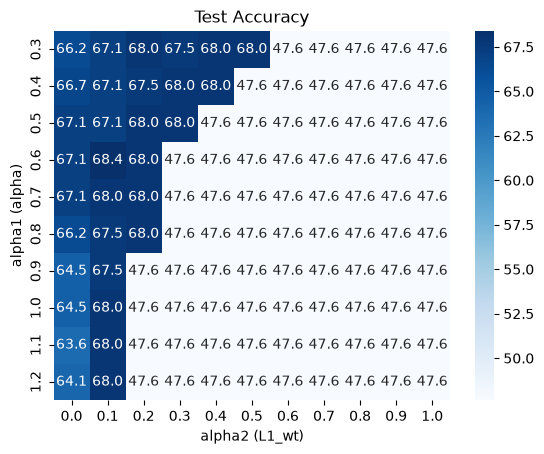

In [26]:
sns.heatmap(results_test, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [28]:
m_reg = sm.GLM(y_train, X_train, family = sm.families.Binomial()).fit_regularized(method = 'elastic_net', alpha = 0.6, L1_wt = 0.1, maxiter = 10000)
predprobs   = m_reg.predict(X_test)
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  68.40%


This is close to the accuracy I got when I used the not as preprocessed data. 

In [29]:
nonzero = m_reg.params[m_reg.params != 0]
print(nonzero.sort_values(key = abs, ascending = False))

x94   -0.133121
x40   -0.052954
x49   -0.037478
x48   -0.016035
x76    0.015181
x22    0.013918
x28   -0.009063
x2     0.005813
x36   -0.002610
dtype: float64


In [30]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 41)

scores = []

for train, test in skf.split(X_train, y_train):
    X_train_fold = X_train[train] 
    X_test_fold = X_train[test] 

    y_train_fold = y_train.iloc[train]
    y_test_fold = y_train.iloc[test]

    model = sm.GLM(y_train_fold, X_train_fold, family = sm.families.Binomial()).fit_regularized(method = 'elastic_net', alpha = 0.6, L1_wt = 0.1, maxiter = 10000)

    predprobs   = model.predict(X_test_fold)
    pred        = np.round(predprobs).astype(int) 
    predictions = ['MS' if i==1 else 'Control' for i in pred] 
    accuracy    = 100*(y_test_fold == pred).mean()

    scores.append(accuracy) 

print("Cross Validation Scores:", scores)
print("Mean Cross Validation Score:", np.mean(scores))

Cross Validation Scores: [np.float64(63.78378378378379), np.float64(66.84782608695652), np.float64(70.1086956521739), np.float64(72.82608695652173), np.float64(63.04347826086957)]
Mean Cross Validation Score: 67.3219741480611


In [31]:
genus_cols = [c for c in data_genus_sex.columns if c not in ["MS", "sex", "disease", "iMSMS_ID"]]

X = data_genus_sex[genus_cols]
#X["sex_M"] = (data_genus_sex["sex"] == "M") .astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 41)

scaler = StandardScaler() 

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

m = sm.GLM(y_train, X_train, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train = np.zeros((len(alpha1), len(alpha2)))
results_test = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = m.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X_train)
        probs_test  = result_reg.predict(X_test)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test))

        results_train[i, j] = acc_train
        results_test[i, j] = acc_test
print(results_train)
print(results_test)

110 will run
[[66.7752443  63.19218241 61.99782845 60.15200869 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [66.01520087 62.64929425 60.47774159 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [65.58089034 62.10640608 60.36916395 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [65.68946797 61.45494028 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [65.90662324 60.80347448 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [65.7980456  60.58631922 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [65.68946797 60.36916395 50.59717698 50.59717698 50.59717698 50.59717698
  50.59717698 50.59717698 50.59717698 50.59717698 50.59717698]
 [65.36373507 60.80347448 50

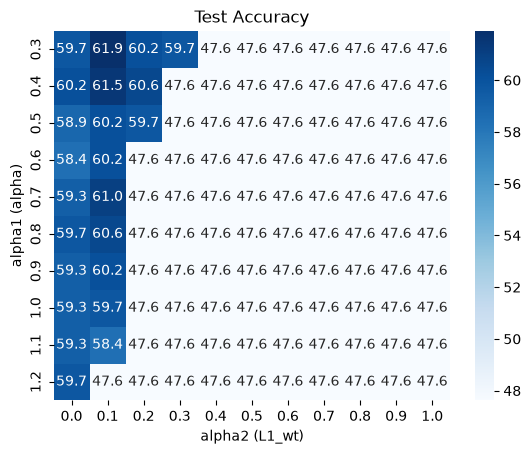

In [32]:
sns.heatmap(results_test, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [33]:
m_reg = sm.GLM(y_train, X_train, family = sm.families.Binomial()).fit_regularized(method = 'elastic_net', alpha = 0.3, L1_wt = 0.1, maxiter = 10000)
predprobs   = m_reg.predict(X_test)
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  61.90%


This is higher than the accuracy I got when I used the not as preprocessed data.

Using only Untreated

In [34]:
print(df1.columns[0])

iMSMS_ID


In [35]:
df1 = pd.read_csv("data/preprocessed/batch_corrected/normalized_zhou_genus.csv") 

df2 = pd.read_csv("data/preprocessed/merged_dfs/zhou_genus_merged_df.csv") # I need extra features: sex, disease, treatment_staus, household  

assert len(df1) == len(df2)
assert (df1["iMSMS_ID"].values == df2["iMSMS_ID"].values).all() 

data_genus_sex_treatment_household = df1
data_genus_sex_treatment_household["sex"] = df2["sex"].values
data_genus_sex_treatment_household["treatment_status"] = df2["treatment_status"].values
data_genus_sex_treatment_household["disease"] = df2["disease"].values 
data_genus_sex_treatment_household["household"] = df2["household"].values 

d = data_genus_sex_treatment_household

untreated_households_only = d.loc[d["treatment_status"] == "Untreated", "household"]

d1 = d[d["household"].isin(untreated_households_only)]

y = (d1["disease"] == "MS").astype(int)

genus_cols = [c for c in d1.columns if c not in ["MS", "sex", "disease", "treatment_status", "iMSMS_ID", "household"]]

X = d1[genus_cols]
X["sex_M"] = (d1["sex"] == "M") .astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 41)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

m = sm.GLM(y_train, X_train, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train = np.zeros((len(alpha1), len(alpha2)))
results_test = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = m.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X_train)
        probs_test  = result_reg.predict(X_test)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test))

        results_train[i, j] = acc_train
        results_test[i, j] = acc_test
print(results_train)
print(results_test)

/var/folders/ly/br2g_8852bl094gy3qx9_qkc0000gn/T/ipykernel_8342/1993521454.py:3: DtypeWarning: Columns (3: ethnicity, 21: spms_year) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv("data/preprocessed/merged_dfs/zhou_genus_merged_df.csv") # I need extra features: sex, disease, treatment_staus, household


110 will run
[[73.05389222 70.35928144 69.76047904 67.36526946 66.76646707 67.06586826
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [73.95209581 70.05988024 68.56287425 66.76646707 67.06586826 49.7005988
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [73.95209581 69.46107784 67.36526946 67.06586826 49.7005988  49.7005988
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [73.95209581 69.46107784 66.76646707 49.7005988  49.7005988  49.7005988
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [73.95209581 68.56287425 67.06586826 49.7005988  49.7005988  49.7005988
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [71.85628743 68.86227545 67.06586826 49.7005988  49.7005988  49.7005988
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [70.95808383 68.26347305 49.7005988  49.7005988  49.7005988  49.7005988
  49.7005988  49.7005988  49.7005988  49.7005988  49.7005988 ]
 [70.95808383 67.36526946 49.70059

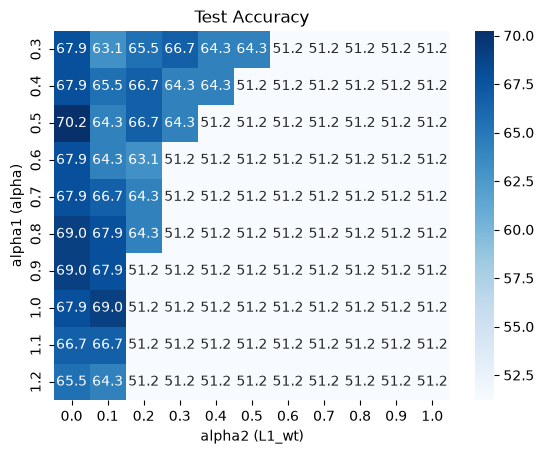

In [36]:
sns.heatmap(results_test, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [37]:
reg_m = m.fit_regularized(method = 'elastic_net', alpha = 0.5, L1_wt = 0.0, maxiter = 10000)
predprobs   = reg_m.predict(X_test)
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  70.24%


In [38]:
d.head()

,iMSMS_ID,escherichia,ruthenibacterium,butyricicoccus,varibaculum,haemophilus,cryptobacterium,erysipelatoclostridium,azospirillum,megamonas,...,veillonella,akkermansia,lachnoclostridium,butyrivibrio,finegoldia,porphyromonas,sex,treatment_status,disease,household
0,71401-0001,-0.262880,1.834220,1.991855,-1.814298,-2.875661,-5.021321,0.568304,-2.764644,-4.995512,...,0.189478,4.790967,2.232759,7.090817,-0.862057,2.411362,M,Treated,MS,7140001
1,71401-0009,-1.465407,2.108809,1.729283,0.469899,-3.458106,-4.503318,0.117325,3.865339,-4.866549,...,-1.048431,-2.305706,2.923619,1.441550,2.052064,0.515222,F,Treated,MS,7140009
2,71401-0017,1.070831,3.475032,3.099399,-1.662950,-3.366503,-4.637942,1.145505,-4.357426,-3.774887,...,1.636488,1.448077,3.536356,1.839589,-2.708417,3.035668,F,Treated,MS,7140017
3,71401-0022,7.760006,2.428759,1.401304,-1.844846,0.366810,-3.970883,3.553336,-3.498719,-3.866483,...,0.826678,0.642523,3.376855,3.154133,-3.388144,1.001036,M,Treated,MS,7140022
4,71401-0027,0.618979,2.588469,1.621120,-0.676442,-2.507712,-3.531036,0.090997,-3.421095,-4.704434,...,-0.655270,5.287732,3.405289,0.844224,0.364226,0.984136,F,Treated,MS,7140027


~2% higher accuracy using just untreated and their household controls + convariate

In [39]:
treated_households_only = d.loc[d["treatment_status"] == "Treated", "household"]
d2 = d[d["household"].isin(treated_households_only)]

y2 = (d2["disease"] == "MS").astype(int)

X2 = d2[genus_cols]
X2["sex_M"] = (d2["sex"] == "M") .astype(int)
X2 = scaler.transform(X2)
X2 = sm.add_constant(X2)

predprobs   = reg_m.predict(X2)
pred        = np.round(predprobs).astype(int) 
predictions = ['MS' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y2 == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  63.90%
